# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de extracción** | Documentos: 23/10/2026 · Audio: 24/10/2026 |
| **Entorno** | VS Code (Jupyter) en laptop, CPU, Python 3.12 — mismas librerías que los grupos `docai` y `audio` del curso (ver celda de instalación) |
| **OCR** | PaddleOCR 3.7.0 (`lang="es"`, configuración base, sin personalización) — Sesión 10 |
| **ASR** | faster-whisper large-v3-turbo (`mobiuslabsgmbh/faster-whisper-large-v3-turbo`, VAD activado) con `voz.py` de la Sesión 13 |
| **Diarización** | Huellas de voz WeSpeaker ResNet34 (`pyannote/wespeaker-voxceleb-resnet34-LM`) + clustering jerárquico (`voz.diarizar`) |

Las versiones exactas instaladas se imprimen en las celdas de configuración de cada parte.

### Corpus A · Documentos (25)

| Tipo | n | Fuente | Licencia |
|---|---|---|---|
| Impresos nítidos | 8 | Wikimedia Commons y Repositorio PUCP (*El Peruano* 1844, *Mercurio Peruano* 1791, *El Comercio* 1839/c.1842/1945, billete de 1879, *La Mesa Peruana* 1867, Constitución de 1823) | Dominio público / CC0 |
| Fotos con sombra, inclinación o poca luz | 8 | Fotografías propias (Jesús María, Lima) | CC BY 4.0 (propia) |
| Manuscritos | 9 | Fotografías propias de pizarras de menú y apuntes | CC BY 4.0 (propia) |

URL, autor y licencia de cada archivo: `datos/fuentes.csv`.

### Corpus B · Audio (≥ 30 min, ≥ 20 clips)

| Fuente | Contenido | Licencia |
|---|---|---|
| [OpenSLR 73](https://www.openslr.org/73/) (Google) | Español peruano leído, hablantes anónimos | CC BY-SA 4.0 |
| [Wikimedia Commons](https://commons.wikimedia.org) | Entrevistas en la calle en El Agustino (Lima) y a una dirigente de Fenmucarinap | CC BY-SA 4.0 |

Al menos un audio tiene 2 o más hablantes (entrevista 2 de El Agustino y un diálogo armado con dos hablantes de OpenSLR 73) para la diarización.

### Ética y datos personales
- Solo archivos con licencia libre; atribución completa en `datos/fuentes.csv`.
- Los originales (imágenes y audio) están en `datos/raw/`, que **no se versiona** (`.gitignore`).
- La lista de nombres reales a seudonimizar está en un archivo privado (`datos/raw/reemplazos_privados.csv`) que tampoco se sube.
- `doc_012` y `doc_014` no se publican como imagen (personas identificables / datos de un particular); solo su texto seudonimizado.

### Cómo ejecutar este notebook
1. Abrir la carpeta `tarea_2/` en VS Code y crear el entorno (una sola vez, en la terminal):
   ```
   py -3.12 -m venv .venv
   .venv\Scripts\activate
   pip install "paddlepaddle>=3.2.1" "paddleocr==3.7.0" faster-whisper jiwer rapidfuzz "pyannote.audio>=4.0.7" soundfile scipy pandas requests plotly kaleido ipykernel
   ```
2. En el notebook, elegir el kernel `.venv` (arriba a la derecha) y ejecutar de arriba hacia abajo.
3. Cada parte (A: OCR, B: audio) relee de disco lo que necesita, así que se puede reiniciar el kernel entre partes si falta memoria.

---
# Parte A · OCR de documentos (Sesión 10)

In [1]:
# Rutas: el notebook está en tarea_2/ y lee las imágenes originales de datos/raw/documentos (no versionado)
from pathlib import Path
BASE = Path.cwd()
assert (BASE / "datos").exists(), "Abre el notebook desde la carpeta tarea_2"
DOCS = BASE / "datos/raw/documentos"
print("Imágenes encontradas:", len([p for p in DOCS.glob("doc_*.*") if p.is_file()]))

Imágenes encontradas: 25


In [ ]:
import torch            # en Windows, torch debe cargarse ANTES que paddle

In [3]:
   import numpy as np
   import pandas as pd
   import torch            # en Windows, torch debe cargarse ANTES que paddle
   import paddle, paddleocr
   from paddleocr import PaddleOCR

c:\Users\valer\Documents\Github\python_intermedio\tarea_2\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
c:\Users\valer\Documents\Github\python_intermedio\tarea_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import hashlib, json, os, time, warnings, logging
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
warnings.filterwarnings("ignore")
for nombre in ("paddlex", "paddleocr", "ppocr"):
    logging.getLogger(nombre).setLevel(logging.ERROR)

from PIL import Image, ImageOps

pd.set_option("display.max_colwidth", 80)
import platform
print("Python", platform.python_version(), "· PaddleOCR", paddleocr.__version__, "· PaddlePaddle", paddle.__version__,
      "· GPU:", paddle.device.is_compiled_with_cuda() and paddle.device.cuda.device_count() > 0)

Python 3.12.15 · PaddleOCR 3.7.0 · PaddlePaddle 3.3.1 · GPU: False


### A.1 Inventario y duplicados por hash

El tipo de cada documento y su fuente vienen de `datos/raw/fuentes_documentos.csv` (la tabla que llené al recolectar).
Dos archivos con el mismo hash SHA-256 son el mismo archivo: se descarta el segundo.

In [7]:
def sha256(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

meta = pd.read_csv(BASE / "datos/raw/fuentes_documentos.csv", dtype=str, sep=None, engine="python", encoding="utf-8-sig").fillna("")
meta.columns = meta.columns.str.strip()
archivos = {p.stem: p for p in sorted(DOCS.glob("doc_*.*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}}

inv = meta[meta["id"].isin(archivos)].copy()
inv["ruta"] = inv["id"].map(archivos)
inv["sha256"] = inv["ruta"].map(sha256)
duplicados = inv[inv.duplicated("sha256", keep="first")]
inv = inv.drop(duplicados.index)

sin_archivo = sorted(set(meta["id"]) - set(archivos))
print(f"Documentos en la tabla: {len(meta)} · con imagen: {len(inv) + len(duplicados)}")
print(f"Duplicados por hash descartados: {len(duplicados)} {list(duplicados['id'])}")
print(f"En la tabla pero sin imagen: {sin_archivo}")
inv["tipo"].value_counts()

Documentos en la tabla: 25 · con imagen: 25
Duplicados por hash descartados: 0 []
En la tabla pero sin imagen: []


tipo
manuscrito    9
impreso       8
foto          8
Name: count, dtype: int64

### A.2 Preprocesamiento

Parámetros (iguales para todos los documentos, fijados antes de ver resultados):
- Se corrige la rotación guardada en los metadatos EXIF de las fotos del celular (`ImageOps.exif_transpose`).
- Se convierte a RGB y, si el lado mayor pasa de 2400 px, se reduce a 2400 px (PaddleOCR redimensiona internamente; esto solo ahorra memoria).
- No se binariza ni se endereza: la Parte 2 debe medir cómo lee el OCR **base** las fotos inclinadas y con sombra.

La copia preprocesada queda en `datos/raw/documentos/proc/`.

In [8]:
PROC = DOCS / "proc"; PROC.mkdir(exist_ok=True)
LADO_MAX = 2400

def preparar(ruta):
    im = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    if max(im.size) > LADO_MAX:
        im.thumbnail((LADO_MAX, LADO_MAX))
    destino = PROC / f"{ruta.stem}.png"
    im.save(destino)
    return destino, im.size

inv[["ruta_proc", "tamano"]] = inv["ruta"].apply(lambda r: pd.Series(preparar(r)))
inv[["id", "tipo", "tamano"]].head()

,id,tipo,tamano
0,doc_001,impreso,"(960, 1360)"
1,doc_002,impreso,"(694, 304)"
2,doc_003,impreso,"(960, 745)"
3,doc_004,impreso,"(960, 1448)"
4,doc_005,impreso,"(500, 722)"


### A.3 OCR con PaddleOCR

Configuración base: `lang="es"`, sin clasificador de orientación de página, sin "planchado" de hojas y sin orientación por línea
(las mismas opciones de la clase). Para cada documento se guarda el **respaldo crudo** (JSON con texto, confianza y caja de cada línea),
la imagen con las cajas dibujadas y los **recortes** de cada línea en `datos/raw/documentos/`.

In [14]:
# enable_mkldnn=False: en Windows/CPU, PaddlePaddle 3.3 con oneDNN falla
OPCIONES_OCR = dict(lang="es", use_doc_orientation_classify=False, use_doc_unwarping=False,
                    use_textline_orientation=False, enable_mkldnn=False)
ocr = PaddleOCR(**OPCIONES_OCR)
MODELO_OCR = f"PaddleOCR {paddleocr.__version__} (lang=es, config. base, CPU sin oneDNN)"

CRUDO = DOCS / "ocr_crudo"; CRUDO.mkdir(exist_ok=True)
CAJAS = DOCS / "ocr_cajas"; CAJAS.mkdir(exist_ok=True)
RECORTES = DOCS / "recortes"; RECORTES.mkdir(exist_ok=True)

filas = []
for d in inv.itertuples():
    t0 = time.perf_counter()
    r = ocr.predict(str(d.ruta_proc))[0]
    seg = time.perf_counter() - t0
    textos, confs = list(r["rec_texts"]), [float(c) for c in r["rec_scores"]]
    cajas = np.asarray(r["rec_boxes"]).reshape(-1, 4) if len(textos) else np.zeros((0, 4))

    try:                                    # respaldo crudo (JSON) e imagen con las cajas
        r.save_to_json(str(CRUDO / f"{d.id}.json"))
        r.save_to_img(str(CAJAS / d.id))
    except Exception as e:
        print("   (no se pudo guardar el respaldo:", e, ")")
    im = Image.open(d.ruta_proc)
    carpeta = RECORTES / d.id; carpeta.mkdir(exist_ok=True)
    for k, (x0, y0, x1, y1) in enumerate(cajas.astype(int)):
        im.crop((x0, y0, x1, y1)).save(carpeta / f"linea_{k:03d}.png")

    filas.append({"id": d.id, "texto_ocr_crudo": "\n".join(textos), "n_lineas": len(textos),
                  "confianza_media": round(float(np.mean(confs)), 3) if confs else 0.0,
                  "segundos_ocr": round(seg, 2)})
    print(f"{d.id} [{d.tipo:<10}] {len(textos):3d} líneas · conf. {filas[-1]['confianza_media']:.2f} · {seg:4.1f} s")

ocr_df = inv.merge(pd.DataFrame(filas), on="id")
ocr_df["modelo_ocr"] = MODELO_OCR

Connecting to https://paddle-model-ecology.bj.bcebos.com/paddlex/PaddleX3.0/fonts/simfang.ttf ...
[==================================================] 100.00%


doc_001 [impreso   ] 138 líneas · conf. 0.97 · 234.2 s
doc_002 [impreso   ]  15 líneas · conf. 0.94 · 15.4 s
doc_003 [impreso   ]  47 líneas · conf. 0.91 · 85.7 s
doc_004 [impreso   ] 286 líneas · conf. 0.93 · 423.0 s
doc_005 [impreso   ] 157 líneas · conf. 0.67 · 225.4 s
doc_006 [impreso   ] 122 líneas · conf. 0.96 · 177.8 s
doc_007 [impreso   ]  23 líneas · conf. 0.99 · 58.8 s
doc_008 [impreso   ]  15 líneas · conf. 0.94 · 24.7 s
doc_009 [foto      ]  28 líneas · conf. 0.98 · 22.7 s
doc_010 [foto      ] 116 líneas · conf. 0.98 · 140.5 s
doc_011 [foto      ] 104 líneas · conf. 0.89 · 114.2 s
doc_012 [foto      ]  36 líneas · conf. 0.99 · 37.9 s
doc_013 [foto      ] 150 líneas · conf. 0.94 · 158.8 s
doc_014 [foto      ]  19 líneas · conf. 0.99 · 24.0 s
doc_015 [foto      ]  17 líneas · conf. 0.95 · 41.1 s
doc_016 [foto      ]  14 líneas · conf. 0.99 · 51.2 s
doc_017 [manuscrito]  42 líneas · conf. 0.95 · 64.2 s
doc_018 [manuscrito]   7 líneas · conf. 0.94 · 20.1 s
doc_019 [manuscrito] 

In [15]:
# Se guarda en datos/raw/ocr_crudo.csv (local, no versionado) para que la Parte B pueda releerlo

cols = ["id", "tipo", "descripcion", "fuente_url", "licencia", "autor", "acceso", "publicar_imagen",
        "sha256", "texto_ocr_crudo", "n_lineas", "confianza_media", "segundos_ocr", "modelo_ocr"]
ocr_df["archivo"] = "datos/raw/documentos/" + ocr_df["ruta"].map(lambda p: p.name)
ocr_df[cols + ["archivo"]].to_csv(BASE / "datos/raw/ocr_crudo.csv", index=False)

> Los resultados del OCR quedaron en `datos/raw/ocr_crudo.csv`. Si el kernel se queda sin memoria, se puede reiniciar y continuar desde la Parte B.

---
# Parte B · Audio a texto (Sesión 13)

In [17]:
# voz.py de la Sesión 13 (mismo código de la clase: VAD, transcripción, diarización, SRT/TXT, seudonimización).
# Se baja una vez del repositorio del curso y queda junto al notebook.
from pathlib import Path
import requests
if not Path("voz.py").exists():
    url = "https://raw.githubusercontent.com/d2cml-ai/Data-Science-Python/main/sessions/13-audio-a-texto/voz.py"
    Path("voz.py").write_text(requests.get(url, timeout=60).text, encoding="utf-8")
print("voz.py listo")

voz.py listo


In [18]:
import hashlib, io, re, time, urllib.parse, warnings, zipfile
from importlib.metadata import version
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import requests
from scipy.io import wavfile
import voz
from voz import SR, Transcriptor, cargar_audio, diarizar, a_srt, a_texto, a_tabla, tramos_de_voz

BASE = Path.cwd()
AUDIO = BASE / "datos/raw/audio"; AUDIO.mkdir(parents=True, exist_ok=True)
ORIG = AUDIO / "originales"; ORIG.mkdir(exist_ok=True)
SALIDAS = AUDIO / "salidas"; SALIDAS.mkdir(exist_ok=True)
UA = {"User-Agent": "tarea2-pucp-python-intermedio/1.0 (proyecto academico)"}
print("faster-whisper", version("faster-whisper"), "· pyannote.audio", version("pyannote.audio"),
      "· dispositivo:", voz.dispositivo())

faster-whisper 1.2.1 · pyannote.audio 4.0.7 · dispositivo: cpu


### B.1 Descarga de las fuentes

- **OpenSLR 73:** los zips pesan cientos de MB, así que se leen **por partes** (peticiones HTTP Range, el mismo truco de `datos.py` de la Sesión 13): solo se bajan las frases que se usan.
- **Wikimedia Commons**: tres entrevistas en español. Se respeta una pausa de 1,5 s entre solicitudes y se usa un `User-Agent` descriptivo.

In [20]:
class ZipRemoto(io.RawIOBase):
    "Archivo remoto que se lee por partes (HTTP Range): zipfile solo pide los bytes que necesita."
    BLOQUE = 4 << 20
    def __init__(self, url):
        self.url, self.pos, self.ini, self.buf = url, 0, 0, b""
        self.size = int(requests.head(url, headers=UA, timeout=60, allow_redirects=True).headers["Content-Length"])
    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.pos
    def seek(self, offset, whence=0):
        self.pos = {0: offset, 1: self.pos + offset, 2: self.size + offset}[whence]
        return self.pos
    def read(self, n=-1):
        n = self.size - self.pos if n is None or n < 0 else min(n, self.size - self.pos)
        if n <= 0:
            return b""
        if not (self.ini <= self.pos and self.pos + n <= self.ini + len(self.buf)):
            fin = min(self.pos + max(n, self.BLOQUE), self.size) - 1
            time.sleep(1)                                    # cortesía con el servidor
            r = requests.get(self.url, headers={**UA, "Range": f"bytes={self.pos}-{fin}"}, timeout=120)
            self.ini, self.buf = self.pos, r.content
        datos = self.buf[self.pos - self.ini:self.pos - self.ini + n]
        self.pos += len(datos)
        return datos

ZIPS, lineas = {}, []
for sexo in ["female", "male"]:
    ZIPS[sexo] = zipfile.ZipFile(ZipRemoto(f"https://www.openslr.org/resources/73/es_pe_{sexo}.zip"))
    filas = [l.split("\t")[:2] for l in ZIPS[sexo].read("line_index.tsv").decode("utf-8").strip().splitlines()]
    t = pd.DataFrame(filas, columns=["id", "texto"])
    t["sexo"] = sexo
    lineas.append(t)
slr = pd.concat(lineas, ignore_index=True)
slr["hablante"] = slr["id"].str.rsplit("_", n=1).str[0]

def frase_audio(fila):
    "Lee una frase de OpenSLR directamente del zip remoto y la pasa a 16 kHz mono."
    sr, x = wavfile.read(io.BytesIO(ZIPS[fila.sexo].read(f"{fila.id}.wav")))
    return cargar_audio((sr, x))

print(f"OpenSLR 73: {len(slr)} frases de {slr['hablante'].nunique()} hablantes")

OpenSLR 73: 5447 frases de 38 hablantes


In [22]:
def bajar_commons(titulo, ruta, intentos=5):
    "Descarga respetando a Wikimedia: si responde 429 (demasiadas solicitudes), espera y reintenta."
    url = "https://commons.wikimedia.org/wiki/Special:FilePath/" + urllib.parse.quote(titulo)
    for k in range(intentos):
        r = requests.get(url, headers=UA, timeout=120)
        if r.status_code == 429:
            espera = int(r.headers.get("Retry-After", 30 * (k + 1)))
            print(f"  Wikimedia pide esperar {espera} s (intento {k + 1}/{intentos})...")
            time.sleep(espera)
            continue
        r.raise_for_status()
        ruta.write_bytes(r.content)
        time.sleep(5)
        return
    raise RuntimeError(f"No se pudo bajar {titulo}: descárgalo a mano en {ruta}")

commons = []
for local, titulo in COMMONS.items():
    ruta = ORIG / local
    if not ruta.exists():
        print("Descargando", local)
        bajar_commons(titulo, ruta)
    commons.append({"archivo": local, "ruta": ruta, "titulo": titulo, "autor": AUTORES[local],
                    "licencia": "CC BY-SA 4.0",
                    "fuente_url": "https://commons.wikimedia.org/wiki/File:" + urllib.parse.quote(titulo.replace(" ", "_"))})
commons = pd.DataFrame(commons)
commons["duracion_seg"] = commons["ruta"].map(lambda p: round(len(cargar_audio(p)) / SR, 1))
commons[["archivo", "duracion_seg", "autor", "licencia"]]

Descargando aurora_coronado.ogg


,archivo,duracion_seg,autor,licencia
0,agustino_1.ogg,136.3,JorgeFlores-pe (Wikimedia Perú),CC BY-SA 4.0
1,agustino_2.ogg,189.0,JorgeFlores-pe (Wikimedia Perú),CC BY-SA 4.0
2,aurora_coronado.ogg,250.6,QM Keen,CC BY-SA 4.0


### B.2 Armado de los clips

- **Entrevistas de Commons:** se cortan en clips de hasta 120 s, buscando el punto más silencioso cerca de cada corte para no partir palabras.
- **OpenSLR 73:** las frases duran ~5 s; se juntan frases de **un mismo hablante** hasta ~75 s por clip, alternando mujeres y hombres, hasta completar al menos 32 min en total.
- **Diálogo de dos hablantes:** frases de una mujer y un hombre de OpenSLR 73 intercaladas (~105 s). Como se sabe quién dice cada frase, sirve para **medir** la diarización.

Todos los clips se guardan como WAV mono de 16 kHz en `datos/raw/audio/clip_XXX.wav` (no se versionan).

In [23]:
OBJETIVO_MIN, SEG_CLIP, MAX_CLIP, MIN_CLIP = 32, 75, 120, 15
PAUSA = np.zeros(int(0.4 * SR), dtype=np.float32)
rng = np.random.default_rng(7)

def guardar(ruta, x):
    wavfile.write(ruta, SR, (np.clip(x, -1, 1) * 32767).astype(np.int16))

def cortes(x, max_seg=MAX_CLIP, min_seg=MIN_CLIP, ventana=6.0):
    "Tramos de hasta max_seg, cortando en el momento más silencioso cerca de cada límite."
    n, maximo = len(x), int(max_seg * SR)
    if n <= maximo:
        return [(0, n)]
    marco = int(0.05 * SR)
    energia = np.sqrt(np.convolve(x.astype(np.float64) ** 2, np.ones(marco) / marco, mode="same"))
    tramos, ini = [], 0
    while n - ini > maximo:
        objetivo = ini + maximo
        a = max(ini + int(min_seg * SR), objetivo - int(ventana * SR))
        corte = a + int(np.argmin(energia[a:objetivo]))
        tramos.append((ini, corte)); ini = corte
    if n - ini < min_seg * SR:
        tramos[-1] = (tramos[-1][0], n)
    else:
        tramos.append((ini, n))
    return tramos

clips, k = [], 0
def nuevo_clip(x, **meta):
    global k
    k += 1
    cid = f"clip_{k:03d}"
    guardar(AUDIO / f"{cid}.wav", x)
    clips.append({"id": cid, "archivo_audio": f"datos/raw/audio/{cid}.wav",
                  "duracion_seg": round(len(x) / SR, 1), **meta})

# 1) entrevistas de Commons
for c in commons.itertuples():
    x = cargar_audio(c.ruta)
    for a, b in cortes(x):
        nuevo_clip(x[a:b], fuente="Wikimedia Commons", origen=c.archivo, autor=c.autor, licencia=c.licencia,
                   fuente_url=c.fuente_url, idioma="es", inicio_origen=round(a / SR, 1), texto_oficial="",
                   multihablante_posible=True)

# 2) diálogo de dos hablantes (con la verdad de quién habla cuándo)
hablantes = {s: list(rng.permutation(sorted(slr.loc[slr.sexo == s, "hablante"].unique()))) for s in ["female", "male"]}
h_mujer, h_hombre = hablantes["female"].pop(), hablantes["male"].pop()
fa, fb = slr[slr.hablante == h_mujer], slr[slr.hablante == h_hombre]
partes, verdad, t, textos = [], [], 0.0, []
for (_, ra), (_, rb) in zip(fa.iterrows(), fb.iterrows()):
    for fila, quien in ((ra, "HABLANTE_1"), (rb, "HABLANTE_2")):
        x = frase_audio(fila)
        verdad.append({"inicio": round(t, 2), "fin": round(t + len(x) / SR, 2), "hablante": quien, "texto": fila.texto})
        textos.append(f"[{quien}] {fila.texto}")
        partes += [x, PAUSA]; t += (len(x) + len(PAUSA)) / SR
    if t >= 105:
        break
nuevo_clip(np.concatenate(partes), fuente="OpenSLR 73", origen=f"diálogo {h_mujer} + {h_hombre}",
           autor="Google (OpenSLR 73)", licencia="CC BY-SA 4.0", fuente_url="https://www.openslr.org/73/",
           idioma="es", inicio_origen=0.0, texto_oficial=" ".join(textos), multihablante_posible=True)
ID_DIALOGO = clips[-1]["id"]
pd.DataFrame(verdad).to_csv(AUDIO / f"{ID_DIALOGO}_hablantes_verdad.csv", index=False)

# 3) clips de un hablante de OpenSLR 73 hasta llegar al objetivo
turnos = [h for par in zip(hablantes["female"], hablantes["male"]) for h in par]
usadas = set()
total = sum(c["duracion_seg"] for c in clips)
i = 0
while total < OBJETIVO_MIN * 60 and turnos:
    h = turnos[i % len(turnos)]; i += 1
    partes, textos, dur = [], [], 0.0
    for fila in slr[(slr.hablante == h) & ~slr.id.isin(usadas)].itertuples():
        x = frase_audio(fila)
        partes += [x, PAUSA]; textos.append(fila.texto); usadas.add(fila.id)
        dur += (len(x) + len(PAUSA)) / SR
        if dur >= SEG_CLIP:
            break
    if not partes:
        turnos.remove(h); continue
    nuevo_clip(np.concatenate(partes), fuente="OpenSLR 73", origen=f"hablante {h}", autor="Google (OpenSLR 73)",
               licencia="CC BY-SA 4.0", fuente_url="https://www.openslr.org/73/", idioma="es",
               inicio_origen=0.0, texto_oficial=" ".join(textos), multihablante_posible=False)
    total += clips[-1]["duracion_seg"]

clips = pd.DataFrame(clips)
print(f"{len(clips)} clips · {clips.duracion_seg.sum() / 60:.1f} min")
clips.groupby("fuente")["duracion_seg"].agg(["count", "sum"]).assign(minutos=lambda d: (d["sum"] / 60).round(1))

24 clips · 32.2 min


,count,sum,minutos
fuente,,,
OpenSLR 73,17,1356.2,22.6
Wikimedia Commons,7,576.0,9.6


### B.3 Limpieza: duplicados y audios sin voz

- Duplicados: mismo hash SHA-256 del WAV.
- Sin voz: el detector de voz (Silero VAD, `voz.tramos_de_voz`) encuentra menos de 3 s de habla en el clip.

In [26]:
def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

clips["sha256"] = clips["id"].map(lambda c: sha256(AUDIO / f"{c}.wav"))
dup = clips[clips.duplicated("sha256", keep="first")]

def segundos_de_voz(cid):
    x = cargar_audio(AUDIO / f"{cid}.wav")
    return round(sum(b - a for a, b in tramos_de_voz(x)), 1)

clips["voz_seg"] = clips["id"].map(segundos_de_voz)
sin_voz = clips[clips["voz_seg"] < 3]

descartes_audio = pd.concat([dup.assign(motivo="duplicado por hash"), sin_voz.assign(motivo="sin voz (VAD < 3 s)")])
clips = clips.drop(descartes_audio.index)
print(f"Descartados: {len(descartes_audio)}")
display(descartes_audio[["id", "origen", "duracion_seg", "voz_seg", "motivo"]])
print(f"Quedan {len(clips)} clips · {clips.duracion_seg.sum() / 60:.1f} min · voz efectiva {clips.voz_seg.sum() / 60:.1f} min")

Descartados: 0


,id,origen,duracion_seg,voz_seg,motivo


Quedan 24 clips · 32.2 min · voz efectiva 20.5 min


### B.4 Transcripción con faster-whisper (VAD activado)

`voz.Transcriptor("faster-whisper")` usa Whisper large-v3-turbo. Con `segmentos()` el VAD corta primero donde hay voz
y solo eso se transcribe: así Whisper no alucina frases en los silencios. Idioma fijado en español.

In [27]:
DISPOSITIVO_ASR = "cuda" if voz.dispositivo() == "cuda" else "cpu"   # en CPU usa int8
asr = Transcriptor("faster-whisper", device=DISPOSITIVO_ASR)
MODELO_ASR = f"faster-whisper large-v3-turbo (VAD on, es, beam 5, {DISPOSITIVO_ASR})"
print(asr, f"· cargado en {asr.segundos_carga:.0f} s")

segmentos, tiempos = {}, {}
for c in clips.itertuples():
    x = cargar_audio(AUDIO / f"{c.id}.wav")
    t0 = time.perf_counter()
    segmentos[c.id] = asr.segmentos(x, idioma="es")
    tiempos[c.id] = time.perf_counter() - t0
    print(f"{c.id} {c.duracion_seg:6.1f} s → {len(segmentos[c.id]):3d} segmentos en {tiempos[c.id]:4.1f} s")

clips["segundos_asr"] = clips["id"].map(tiempos).round(2)
clips["factor_tiempo_real"] = (clips["segundos_asr"] / clips["duracion_seg"]).round(3)

[2026-10-24 20:12:28,305] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/mobiuslabsgmbh/faster-whisper-large-v3-turbo/revision/main "HTTP/1.1 307 Temporary Redirect"
[2026-10-24 20:12:28,454] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/dropbox-dash/faster-whisper-large-v3-turbo/revision/main "HTTP/1.1 200 OK"
[2026-10-24 20:12:28,602] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/mobiuslabsgmbh/faster-whisper-large-v3-turbo/tree/0a363e9161cbc7ed1431c9597a8ceaf0c4f78fcf?recursive=true&expand=false "HTTP/1.1 307 Temporary Redirect"
[2026-10-24 20:12:28,742] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/dropbox-dash/faster-whisper-large-v3-turbo/tree/0a363e9161cbc7ed1431c9597a8ceaf0c4f78fcf?recursive=true&expand=false "HTTP/1.1 200 OK"
[2026-10-24 20:12:28,951] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/mobiuslabsgmbh/fast

Transcriptor(faster-whisper (Whisper turbo en CTranslate2) en cpu) · cargado en 452 s


[2026-10-24 20:20:00,901] [    INFO] transcribe.py:895 - VAD filter removed 00:19.184 of audio
[2026-10-24 20:21:22,198] [    INFO] transcribe.py:881 - Processing audio with duration 00:20.504
[2026-10-24 20:21:22,304] [    INFO] transcribe.py:895 - VAD filter removed 00:00.784 of audio


clip_001  115.8 s →  22 segmentos en 81.9 s


[2026-10-24 20:21:37,589] [    INFO] transcribe.py:881 - Processing audio with duration 01:59.279


...

clip_022   77.2 s →  13 segmentos en 32.5 s


[2026-10-24 20:36:46,709] [    INFO] transcribe.py:895 - VAD filter removed 00:37.771 of audio
[2026-10-24 20:37:21,293] [    INFO] transcribe.py:881 - Processing audio with duration 01:19.744


clip_023   80.5 s →  12 segmentos en 35.0 s


[2026-10-24 20:37:21,711] [    INFO] transcribe.py:895 - VAD filter removed 00:43.264 of audio


clip_024   79.7 s →   8 segmentos en 35.2 s


### B.5 Diarización (quién habla cuándo)

Se aplica a los audios que pueden tener varias voces: las entrevistas de Commons y el diálogo armado.
Los clips de OpenSLR de un solo lector quedan con `n_hablantes = 1` (lo dice la fuente).
En el diálogo se compara con la verdad conocida.

In [28]:
for c in clips.itertuples():
    if c.multihablante_posible and segmentos[c.id]:
        x = cargar_audio(AUDIO / f"{c.id}.wav")
        n = 2 if c.id == ID_DIALOGO else None          # en las entrevistas no sabemos cuántos hay: decide el umbral
        segmentos[c.id] = diarizar(x, segmentos[c.id], n_hablantes=n)

def n_hablantes(cid):
    hs = {s.hablante for s in segmentos[cid] if s.hablante}
    return max(len(hs), 1)

clips["n_hablantes"] = clips["id"].map(n_hablantes)

# Verificación en el diálogo: % de segmentos asignados al hablante correcto
verdad = pd.read_csv(AUDIO / f"{ID_DIALOGO}_hablantes_verdad.csv")
def quien_en(t):
    f = verdad[(verdad.inicio <= t) & (verdad.fin >= t)]
    return f.hablante.iloc[0] if len(f) else None
pares = pd.DataFrame([{"pred": s.hablante, "real": quien_en((s.inicio + s.fin) / 2)} for s in segmentos[ID_DIALOGO]]).dropna()
mapa = pares.groupby("pred")["real"].agg(lambda v: v.mode().iloc[0])
acierto = (pares["pred"].map(mapa) == pares["real"]).mean()
print(f"Diálogo {ID_DIALOGO}: {len(pares)} segmentos, {acierto:.0%} atribuidos al hablante correcto")
clips[clips.multihablante_posible][["id", "origen", "duracion_seg", "n_hablantes"]]

[2026-10-24 20:46:31,432] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/pyannote/wespeaker-voxceleb-resnet34-LM/resolve/main/pytorch_model.bin "HTTP/1.1 302 Found"
[2026-10-24 20:46:31,561] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/pyannote/wespeaker-voxceleb-resnet34-LM/xet-read-token/837717ddb9ff5507820346191109dc79c958d614 "HTTP/1.1 200 OK"


Diálogo clip_008: 14 segmentos, 100% atribuidos al hablante correcto


,id,origen,duracion_seg,n_hablantes
0,clip_001,agustino_1.ogg,115.8,2
1,clip_002,agustino_1.ogg,20.5,3
2,clip_003,agustino_2.ogg,119.3,3
3,clip_004,agustino_2.ogg,69.7,4
4,clip_005,aurora_coronado.ogg,114.5,2
5,clip_006,aurora_coronado.ogg,117.5,2
6,clip_007,aurora_coronado.ogg,18.7,2
7,clip_008,diálogo pef_06136 + pem_02436,110.3,2


In [49]:
total_clips = len(clips)
total_min = clips["duracion_seg"].sum() / 60
print(f"Clips: {total_clips}  |  Minutos: {total_min:.1f}  |  Multihablante: {(clips['n_hablantes'] > 1).sum()}")
print("Cumple ≥20 clips:", total_clips >= 20, "| Cumple ≥30 min:", total_min >= 30)
clips.groupby("fuente")["duracion_seg"].agg(clips="count", minutos=lambda s: round(s.sum() / 60, 1))

Clips: 24  |  Minutos: 32.2  |  Multihablante: 8
Cumple ≥20 clips: True | Cumple ≥30 min: True


,clips,minutos
fuente,,
OpenSLR 73,17,22.6
Wikimedia Commons,7,9.6


In [29]:
# Texto corrido de cada clip (todavía sin seudonimizar; los archivos SRT/TXT se exportan después de seudonimizar)
def con_marcas(segs):
    "Texto corrido; si hay diarización, cada turno empieza con [HABLANTE_n]."
    if not any(s.hablante for s in segs):
        return " ".join(s.texto for s in segs).strip()
    turnos = []
    for s in segs:
        etiqueta = f"[HABLANTE_{s.hablante.lstrip('H')}]"
        if turnos and turnos[-1][0] == etiqueta:
            turnos[-1][1].append(s.texto)
        else:
            turnos.append((etiqueta, [s.texto]))
    return " ".join(f"{e} {' '.join(t)}" for e, t in turnos)

clips["texto_asr_crudo"] = clips["id"].map(lambda c: con_marcas(segmentos[c]))
clips["modelo_asr"] = MODELO_ASR
print("Ejemplo de texto con marcas de hablante:\n", clips.loc[clips.id == ID_DIALOGO, "texto_asr_crudo"].iloc[0][:500])

Ejemplo de texto con marcas de hablante:
 [HABLANTE_1] ¿A qué hora cierra el mercado de flores? [HABLANTE_2] ¿Cuáles son las noticias más recientes del terremoto? [HABLANTE_1] Las tejas rojas del tejado no son de México, son de Texas [HABLANTE_2] Te recomiendo la crema que se llama Solución X, es una nueva loción médica [HABLANTE_1] El caballo está amarrado [HABLANTE_2] Busca regalos que cuesten entre dos mil y tres mil pesos [HABLANTE_1] ¿Usted está interesado en las olimpiadas o en el mundial de gimnasia que menciono después? [HABLANT



---
# Seudonimización (documentos y audio)

1. **Nombres de personas particulares:** la lista de nombres reales y su seudónimo está en `datos/raw/reemplazos_privados.csv`
   (columnas `nombre,seudonimo`). Ese archivo **no se versiona**: si estuviera en el notebook, publicaría los nombres que quiero ocultar.
   Se reemplazan con `voz.seudonimizar`, que también atrapa variantes mal escritas por el OCR/ASR.
2. **DNI:** 8 dígitos precedidos de "DNI" → `[DNI]`.
3. **Teléfonos de particulares:** en los documentos marcados como no publicables (`doc_014`), los celulares de 9 dígitos → `[TELEFONO]`.
   Los teléfonos de negocios en carteles públicos no son datos personales y se mantienen.
4. **Revisión humana:** después de esta celda leí todos los textos y agregué a la lista los nombres que aparecieron.

Las figuras públicas e históricas (alcaldes en una placa, personajes de periódicos antiguos) no se seudonimizan.

In [52]:
from rapidfuzz import fuzz  # noqa: F401  (lo usa voz.seudonimizar)

ruta_reemplazos = BASE / "datos/raw/reemplazos_privados.csv"
if not ruta_reemplazos.exists():
    pd.DataFrame(columns=["nombre", "seudonimo"]).to_csv(ruta_reemplazos, index=False)
reemplazos = dict(pd.read_csv(ruta_reemplazos, dtype=str, sep=None, engine="python", encoding="utf-8-sig").dropna().values)
print(f"Nombres en la lista privada: {len(reemplazos)}")

RE_DNI = re.compile(r"\bDNI\W{0,3}\d{8}\b", re.I)
RE_CEL = re.compile(r"\b9\d{2}[\s-]?\d{3}[\s-]?\d{3}\b")
PRIVADOS = {"doc_014"}

def seudonimizar(texto, privado=False):
    "Devuelve (texto seudonimizado, número de entidades reemplazadas)."
    n = 0
    salida = texto or ""
    for nombre, seud in reemplazos.items():
        antes = salida.count(seud)
        salida = voz.seudonimizar(salida, {nombre: seud})
        n += salida.count(seud) - antes
    salida, k = RE_DNI.subn("[DNI]", salida); n += k
    if privado:
        salida, k = RE_CEL.subn("[TELEFONO]", salida); n += k
    return salida, n

docs = pd.read_csv(BASE / "datos/raw/ocr_crudo.csv", dtype={"id": str}).fillna({"texto_ocr_crudo": ""})
docs[["texto_ocr", "entidades_reemplazadas"]] = docs.apply(
    lambda d: pd.Series(seudonimizar(d.texto_ocr_crudo, d.id in PRIVADOS)), axis=1)
# Audio: se seudonimiza segmento por segmento y con eso se exportan CSV, SRT y TXT (datos/raw/audio/salidas/)
from voz import Segmento
entidades = {}
for cid, segs in segmentos.items():
    nuevos, n = [], 0
    for sg in segs:
        texto, k = seudonimizar(sg.texto)
        nuevos.append(Segmento(sg.inicio, sg.fin, texto, sg.hablante)); n += k
    segmentos[cid], entidades[cid] = nuevos, n
    a_tabla(nuevos).to_csv(SALIDAS / f"{cid}.csv", index=False)
    (SALIDAS / f"{cid}.srt").write_text(a_srt(nuevos), encoding="utf-8")
    (SALIDAS / f"{cid}.txt").write_text(a_texto(nuevos), encoding="utf-8")
clips["texto_asr"] = clips["id"].map(lambda c: con_marcas(segmentos[c]))
clips["entidades_reemplazadas"] = clips["id"].map(entidades)
print(f"Exportados {len(segmentos)} clips × (CSV, SRT, TXT) en {SALIDAS}")

resumen_seud = pd.DataFrame({
    "modalidad": ["documentos", "audio"],
    "registros con reemplazos": [(docs.entidades_reemplazadas > 0).sum(), (clips.entidades_reemplazadas > 0).sum()],
    "entidades reemplazadas": [docs.entidades_reemplazadas.sum(), clips.entidades_reemplazadas.sum()],
})
resumen_seud

Nombres en la lista privada: 7


[2026-10-24 21:40:43,222] [    INFO] _tmpfile.py:157 - TemporaryDirectory.cleanup() worked.
[2026-10-24 21:40:43,228] [    INFO] _tmpfile.py:181 - shutil.rmtree worked.


Exportados 24 clips × (CSV, SRT, TXT) en c:\Users\valer\Documents\Github\python_intermedio\tarea_2\datos\raw\audio\salidas


,modalidad,registros con reemplazos,entidades reemplazadas
0,documentos,1,3
1,audio,3,11


In [53]:
#Revision manual
print(docs.loc[docs.id == "doc_014", "texto_ocr"].iloc[0])

[TELEFONO]-[TELEFONO] [PERSONA_1]
REMATEDEARTÍCULOS
NUEVOSYUSADOS
POR CIERRE DE LOCAL
AI30% DE SU PRECIÓ.
MOLDES DE YESO P/VELAS
REBAJAAL30%Y40%
ENOTROSARTÍCULOS
ADORNOS CHINOS.
CANDELABROS P/VELAS
ADORNOS DE NAVIDAD
MÁQUINAS REGISTRADORAS
MÁQUINAS ETIQUETADORAS
MÁQUINA ENCAPSULADORA
ANDAMIOS DE FIERRO
LLAVEROS Y OTROS ARTÍCULOS
2 MÁQUINAS DE COSER
BISUTERÍA (ACERO BAÑADO EN ORO)
VITRINAS DE DIFERENTES TAMAÑOS


# Limpieza de documentos

- Duplicados por hash: ya se quitaron en la Parte A (se reporta abajo).
- **Ilegibles:** un documento se considera ilegible si el OCR no recupera texto útil (menos de 15 caracteres alfanuméricos).
  Los documentos con poca confianza **no** se descartan: son justamente los casos difíciles que la Parte 2 debe analizar.

In [54]:
docs["caracteres"] = docs["texto_ocr"].str.count(r"\w")
ilegibles = docs[docs["caracteres"] < 15]
print(f"Ilegibles (sin texto útil): {len(ilegibles)} {list(ilegibles.id)}")
print(f"Baja confianza (< 0.70), se conservan: {list(docs.loc[docs.confianza_media < 0.70, 'id'])}")
docs_validos = docs.drop(ilegibles.index)
MINIMOS = {"impreso": 8, "foto": 8, "manuscrito": 9}
cuenta = docs_validos["tipo"].value_counts()
for tipo, minimo in MINIMOS.items():
    n = int(cuenta.get(tipo, 0))
    print(f"{tipo:<11} {n:2d} / {minimo}  {'OK' if n >= minimo else '¡FALTAN! reemplazar el documento ilegible y volver a correr'}")
print(f"Total válidos: {len(docs_validos)} (mínimo 25)")

Ilegibles (sin texto útil): 0 []
Baja confianza (< 0.70), se conservan: ['doc_005']
impreso      8 / 8  OK
foto         8 / 8  OK
manuscrito   9 / 9  OK
Total válidos: 25 (mínimo 25)


# Análisis exploratorio

Tres gráficos con Plotly Express. El título de cada uno resume lo que muestra (se calcula con los datos).

In [55]:
%pip install -q nbformat kaleido

Note: you may need to restart the kernel to use updated packages.


In [56]:
import plotly.express as px
from IPython.display import Image as ImagenPNG, display

try:                                   # kaleido exporta PNG; necesita Chrome y lo descarga una sola vez
    import kaleido
    kaleido.get_chrome_sync()
except Exception as e:
    print("Sin exportación PNG (los gráficos interactivos igual se ven):", e)

def mostrar(fig):
    "Gráfico interactivo en VS Code y, además, una copia PNG para que se vea en GitHub."
    fig.update_layout(template="plotly_white", title_x=0.02, margin=dict(t=80))
    fig.show()
    try:
        display(ImagenPNG(fig.to_image(format="png", width=900, height=450, scale=1)))
    except Exception as e:
        print("(sin copia PNG:", e, ")")

ORDEN_TIPO = ["impreso", "foto", "manuscrito"]
COLORES = {"impreso": "#2a78d6", "foto": "#eb6834", "manuscrito": "#0ca30c"}

[2026-10-24 21:41:12,643] [    INFO] _cli_utils.py:143 - Using last known good version of chrome


[2026-10-24 21:14:02,846] [    INFO] _tmpfile.py:157 - TemporaryDirectory.cleanup() worked.
[2026-10-24 21:14:02,851] [    INFO] _tmpfile.py:181 - shutil.rmtree worked.


[2026-10-24 21:14:03,022] [    INFO] chromium.py:164 - Chromium init'ed with kwargs {}
[2026-10-24 21:14:03,031] [    INFO] chromium.py:196 - Found chromium path: C:\Users\valer\AppData\Local\plotly\choreographer\deps\chrome-win64\chrome.exe
[2026-10-24 21:14:03,033] [    INFO] _tmpfile.py:81 - Temp directory created: C:\Users\valer\AppData\Local\Temp\tmp_zcewq94.
[2026-10-24 21:14:03,038] [    INFO] browser_async.py:128 - Opening browser.
[2026-10-24 21:14:03,048] [    INFO] _tmpfile.py:81 - Temp directory created: C:\Users\valer\AppData\Local\Temp\tmpksob1urt.
[2026-10-24 21:14:03,056] [    INFO] chromium.py:210 - Temporary directory at: C:\Users\valer\AppData\Local\Temp\tmpksob1urt
[2026-10-24 21:14:05,339] [    INFO] kaleido.py:240 - Conforming 1 to file:///C:/Users/valer/AppData/Local/Temp/tmp_zcewq94/index.html
[2026-10-24 21:14:08,263] [    INFO] kaleido.py:307 - Getting tab from queue (has 1)
[2026-10-24 21:14:08,267] [    INFO] kaleido.py:313 - Got 6051
[2026-10-24 21:14:08,50

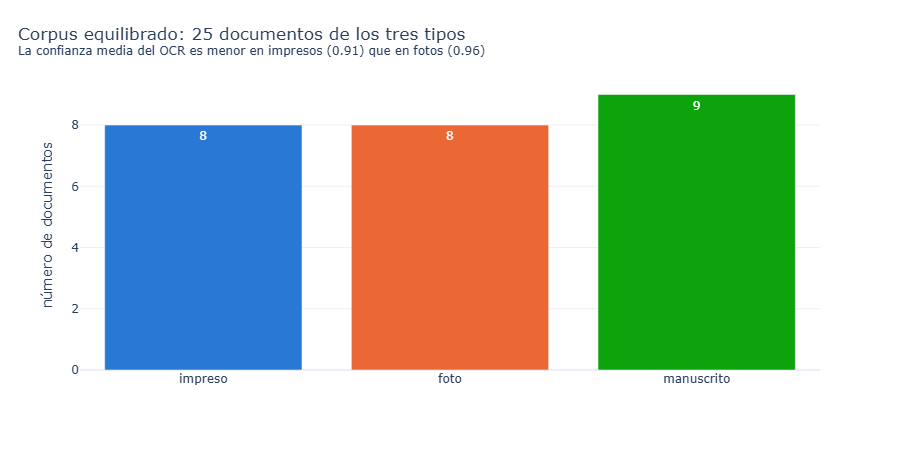

In [40]:
# 1) Documentos por tipo, con la confianza media del OCR
por_tipo = (docs_validos.groupby("tipo")
            .agg(documentos=("id", "count"), confianza=("confianza_media", "mean"))
            .reindex(ORDEN_TIPO).reset_index())
peor = por_tipo.sort_values("confianza").iloc[0]
mejor = por_tipo.sort_values("confianza").iloc[-1]
fig = px.bar(por_tipo, x="tipo", y="documentos", color="tipo", color_discrete_map=COLORES, text="documentos",
             hover_data={"confianza": ":.2f"},
             title=(f"Corpus equilibrado: {len(docs_validos)} documentos de los tres tipos<br>"
                    f"<sup>La confianza media del OCR es menor en {peor.tipo}s ({peor.confianza:.2f}) "
                    f"que en {mejor.tipo}s ({mejor.confianza:.2f})</sup>"))
fig.update_layout(showlegend=False, yaxis_title="número de documentos", xaxis_title="")
mostrar(fig)

[2026-10-24 21:44:33,996] [    INFO] chromium.py:164 - Chromium init'ed with kwargs {}
[2026-10-24 21:44:34,008] [    INFO] chromium.py:196 - Found chromium path: C:\Users\valer\AppData\Local\plotly\choreographer\deps\chrome-win64\chrome.exe
[2026-10-24 21:44:34,013] [    INFO] _tmpfile.py:81 - Temp directory created: C:\Users\valer\AppData\Local\Temp\tmp66fg9ura.
[2026-10-24 21:44:34,019] [    INFO] browser_async.py:128 - Opening browser.
[2026-10-24 21:44:34,027] [    INFO] _tmpfile.py:81 - Temp directory created: C:\Users\valer\AppData\Local\Temp\tmp2zx2jjda.
[2026-10-24 21:44:34,037] [    INFO] chromium.py:210 - Temporary directory at: C:\Users\valer\AppData\Local\Temp\tmp2zx2jjda
[2026-10-24 21:44:35,510] [    INFO] kaleido.py:240 - Conforming 1 to file:///C:/Users/valer/AppData/Local/Temp/tmp66fg9ura/index.html
[2026-10-24 21:44:38,487] [    INFO] kaleido.py:307 - Getting tab from queue (has 1)
[2026-10-24 21:44:38,488] [    INFO] kaleido.py:313 - Got E33A
[2026-10-24 21:44:38,70

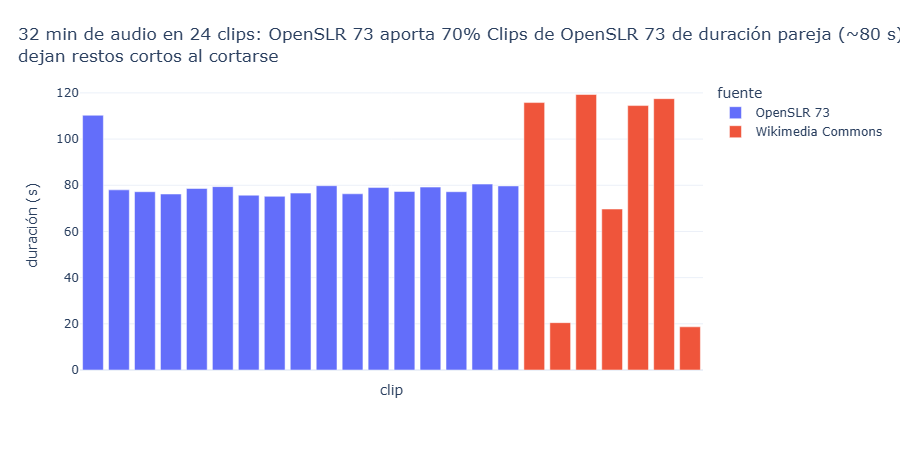

In [61]:
# 2) Duración de cada clip por fuente
clips["minutos"] = clips["duracion_seg"] / 60
dom = clips.groupby("fuente")["minutos"].sum().sort_values(ascending=False)
media = clips.groupby("fuente")["duracion_seg"].mean()
fig = px.bar(clips.sort_values(["fuente", "id"]), x="id", y="duracion_seg", color="fuente",
             hover_data=["origen", "n_hablantes"],
             title=(f"{clips.minutos.sum():.0f} min de audio en {len(clips)} clips: {dom.index[0]} aporta "
                    f"{dom.iloc[0] / dom.sum():.0%} Clips de {dom.index[0]} de duración pareja "
                    f"(~{media[dom.index[0]]:.0f} s); las entrevistas reales aportan {dom.get('Wikimedia Commons', 0):.0f} min "
                    f"y<br>dejan restos cortos al cortarse</sup>"))
fig.update_layout(xaxis_title="clip", yaxis_title="duración (s)", xaxis={"showticklabels": False})
mostrar(fig)

[2026-10-24 21:44:50,800] [    INFO] _tmpfile.py:157 - TemporaryDirectory.cleanup() worked.


[2026-10-24 21:44:50,804] [    INFO] _tmpfile.py:181 - shutil.rmtree worked.


[2026-10-24 21:44:50,897] [    INFO] chromium.py:164 - Chromium init'ed with kwargs {}
[2026-10-24 21:44:50,909] [    INFO] chromium.py:196 - Found chromium path: C:\Users\valer\AppData\Local\plotly\choreographer\deps\chrome-win64\chrome.exe
[2026-10-24 21:44:50,917] [    INFO] _tmpfile.py:81 - Temp directory created: C:\Users\valer\AppData\Local\Temp\tmph4rte361.
[2026-10-24 21:44:50,922] [    INFO] browser_async.py:128 - Opening browser.
[2026-10-24 21:44:50,927] [    INFO] _tmpfile.py:81 - Temp directory created: C:\Users\valer\AppData\Local\Temp\tmp6wek1ncq.
[2026-10-24 21:44:50,934] [    INFO] chromium.py:210 - Temporary directory at: C:\Users\valer\AppData\Local\Temp\tmp6wek1ncq
[2026-10-24 21:44:52,402] [    INFO] kaleido.py:240 - Conforming 1 to file:///C:/Users/valer/AppData/Local/Temp/tmph4rte361/index.html
[2026-10-24 21:44:55,353] [    INFO] kaleido.py:307 - Getting tab from queue (has 1)
[2026-10-24 21:44:55,359] [    INFO] kaleido.py:313 - Got 9FC7
[2026-10-24 21:44:55,65

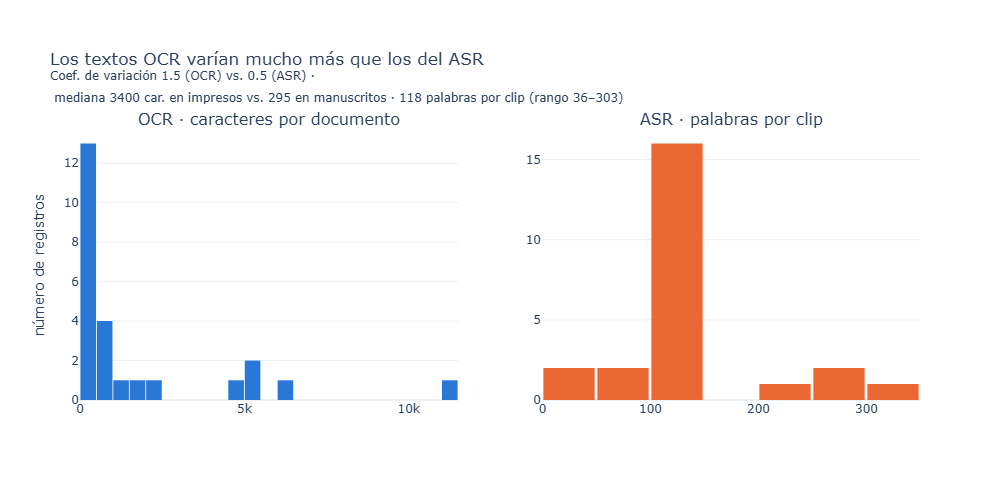

In [62]:
# 3) Longitud de los textos extraídos: caracteres OCR y palabras ASR (cada panel con sus propios intervalos)
from plotly.subplots import make_subplots
import plotly.graph_objects as go

docs_validos["longitud"] = docs_validos["texto_ocr"].str.len()
clips["palabras_asr"] = clips["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()
med = docs_validos.groupby("tipo")["longitud"].median().reindex(ORDEN_TIPO)
cv_ocr = docs_validos["longitud"].std() / docs_validos["longitud"].mean()
cv_asr = clips["palabras_asr"].std() / clips["palabras_asr"].mean()

fig = make_subplots(rows=1, cols=2, subplot_titles=("OCR · caracteres por documento", "ASR · palabras por clip"))
fig.add_trace(go.Histogram(x=docs_validos["longitud"], nbinsx=25, marker_color="#2a78d6"), row=1, col=1)
fig.add_trace(go.Histogram(x=clips["palabras_asr"], nbinsx=12, marker_color="#eb6834"), row=1, col=2)
fig.update_yaxes(title_text="número de registros", row=1, col=1)
fig.update_layout(
    template="plotly_white", showlegend=False, bargap=0.05,
    margin=dict(t=130), title_x=0.02,
    title=(f"Los textos OCR varían {'mucho más que' if cv_ocr > 1.5 * cv_asr else 'tanto como'} los del ASR<br>"
           f"<sup>Coef. de variación {cv_ocr:.1f} (OCR) vs. {cv_asr:.1f} (ASR) ·<br> "
           f"mediana {med['impreso']:.0f} car. en impresos vs. {med['manuscrito']:.0f} en manuscritos · "
           f"{clips.palabras_asr.median():.0f} palabras por clip (rango {clips.palabras_asr.min()}–{clips.palabras_asr.max()})</sup>"),
)
fig.show()
try:
    display(ImagenPNG(fig.to_image(format="png", width=1000, height=480, scale=1)))
except Exception as e:
    print("(sin copia PNG:", e, ")")

La longitud del texto OCR depende sobre todo del tipo de documento (coeficiente de variación 1.5). Los impresos tienen una mediana de 3 400 caracteres, y la portada de El Comercio 1945 supera los 11 000, mientras que los manuscritos tienen una mediana de 295. En audio la variación es menor (0.5), porque las palabras siguen la duración del clip: los 16 clips de OpenSLR (~80 s) se concentran entre 100 y 150 palabras, y los extremos son las entrevistas de Commons (36 palabras en un resto de 20 s y 303 en un tramo de 2 min con habla rápida).

# Validación

Los 3 documentos con el OCR más largo y más corto, y los 3 clips más largos y más cortos, para comprobar que coinciden con los histogramas.

In [63]:
cols_d = ["id", "tipo", "descripcion", "longitud", "confianza_media"]
print("Documentos con MÁS texto OCR"); display(docs_validos.nlargest(3, "longitud")[cols_d])
print("Documentos con MENOS texto OCR"); display(docs_validos.nsmallest(3, "longitud")[cols_d])
cols_a = ["id", "fuente", "origen", "duracion_seg", "palabras_asr", "n_hablantes"]
print("Clips más largos"); display(clips.nlargest(3, "duracion_seg")[cols_a])
print("Clips más cortos"); display(clips.nsmallest(3, "duracion_seg")[cols_a])
for d in docs_validos.nsmallest(3, "longitud").itertuples():
    print(f"\n{d.id} ({d.tipo}): {d.texto_ocr[:200]!r}")

Documentos con MÁS texto OCR


,id,tipo,descripcion,longitud,confianza_media
3,doc_004,impreso,El Comercio 1945 (Hitler),11217,0.929
4,doc_005,impreso,"El Comercio, Lima, 4 de mayo de 1839 (primer número)",6154,0.674
5,doc_006,impreso,"El Comercio, Lima, c. 1842, ""Perú y Ecuador"" (pág. 826)",5162,0.962


Documentos con MENOS texto OCR


,id,tipo,descripcion,longitud,confianza_media
17,doc_018,manuscrito,"Apuntes de vectores en R3 (lapicero, recortado sin nombre)",138,0.939
15,doc_016,foto,"Cartel municipal #ModoNiñez (sombra de hojas, letra cursiva)",172,0.986
1,doc_002,impreso,"Billete de 20 soles, República del Perú, 1879",199,0.943


Clips más largos


,id,fuente,origen,duracion_seg,palabras_asr,n_hablantes
2,clip_003,Wikimedia Commons,agustino_2.ogg,119.3,260,3
5,clip_006,Wikimedia Commons,aurora_coronado.ogg,117.5,303,2
0,clip_001,Wikimedia Commons,agustino_1.ogg,115.8,227,2


Clips más cortos


,id,fuente,origen,duracion_seg,palabras_asr,n_hablantes
6,clip_007,Wikimedia Commons,aurora_coronado.ogg,18.7,45,2
1,clip_002,Wikimedia Commons,agustino_1.ogg,20.5,36,3
3,clip_004,Wikimedia Commons,agustino_2.ogg,69.7,117,4



doc_018 (manuscrito): 'TARED EN CHADJE:\n1. Do) vectores de R3\na:=(3,5,7.5)\n5:=(8,10,20)\n2. JumAr Vecronts y Mulriplicon vecrenes\na+b:=(11,15,27.5)\n35:=(24,30,60)'

doc_016 (foto): 'Ponte en\nTiempo de\nEl\n#Modo\nNiñez\nhoy no regresa.\nrie, juega y comparte\nMunicipalidad de\nMinisterio\nGobierno del Perú\nJesús María\nPERÚ\nde la Mujer y\nPoblaciones Vulnerables'

doc_002 (impreso): 'RepiblicadelPeru\n20\nPORTADOR\nPAGARÁ AL\nB322426\nB322426\nVeinteSoles\nNeinteSoles\nleyes de2rdeEncro\ny4deTebreodes879.\nPORLAJUNTA\nY DE VIJILANCIA DE\nADMINISTRADORA\nLAEMISION FISCAL\nLIMA JUNIO 30 DE 1879.'


# Exportación

`texto_referencia` queda vacío: se completa a mano en la Parte 2, solo para la muestra de evaluación.

In [64]:
DATOS = BASE / "datos"

documentos = pd.DataFrame({
    "id": docs_validos["id"], "archivo": docs_validos["archivo"], "tipo": docs_validos["tipo"],
    "fuente": docs_validos["autor"] + " · " + docs_validos["licencia"],
    "texto_ocr": docs_validos["texto_ocr"], "modelo_ocr": docs_validos["modelo_ocr"], "texto_referencia": "",
    "descripcion": docs_validos["descripcion"], "confianza_media": docs_validos["confianza_media"],
    "publicar_imagen": docs_validos["publicar_imagen"],
})
transcripciones = pd.DataFrame({
    "id": clips["id"], "archivo_audio": clips["archivo_audio"], "duracion_seg": clips["duracion_seg"],
    "idioma": "es (español peruano según la fuente)", "texto_asr": clips["texto_asr"], "modelo_asr": clips["modelo_asr"],
    "n_hablantes": clips["n_hablantes"], "texto_referencia": "",
    "fuente": clips["fuente"], "origen": clips["origen"], "segundos_asr": clips["segundos_asr"],
})
fuentes = pd.concat([
    pd.DataFrame({"id": docs_validos["id"], "modalidad": "documento", "fuente_url": docs_validos["fuente_url"],
                  "licencia": docs_validos["licencia"], "acceso": docs_validos["acceso"],
                  "autor": docs_validos["autor"], "titulo": docs_validos["descripcion"]}),
    pd.DataFrame({"id": clips["id"], "modalidad": "audio", "fuente_url": clips["fuente_url"],
                  "licencia": clips["licencia"],
                  "acceso": np.where(clips["fuente"] == "OpenSLR 73",
                                     "Descarga pública: es_pe_female.zip / es_pe_male.zip; clip armado en este notebook",
                                     "Descarga pública desde fuente_url; clip recortado en este notebook"),
                  "autor": clips["autor"], "titulo": clips["origen"]}),
], ignore_index=True)

documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
fuentes.to_csv(DATOS / "fuentes.csv", index=False)
# respaldo privado (no versionado) con lo que necesita la Parte 2: texto oficial de OpenSLR y tiempos
clips.drop(columns=["texto_asr_crudo"]).to_csv(AUDIO / "inventario_clips.csv", index=False)

for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv → {df.shape}")
display(documentos.head())
display(transcripciones.head())

datos/documentos.csv → (25, 10)
datos/transcripciones.csv → (24, 11)
datos/fuentes.csv → (49, 7)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,descripcion,confianza_media,publicar_imagen
0,doc_001,datos/raw/documentos/doc_001.png,impreso,El Peruano (periódico oficial) · Dominio público,EL PERUANO\nVale\nSE PUBLICA MIERCOLES Y SABADO DE CADA SEMANA.\nUn real.\nN...,"PaddleOCR 3.7.0 (lang=es, config. base, CPU sin oneDNN)",,"El Peruano, Lima, 10 de abril de 1844",0.967,si
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,República del Perú / American Bank Note Co. · Dominio público,RepiblicadelPeru\n20\nPORTADOR\nPAGARÁ AL\nB322426\nB322426\nVeinteSoles\nNe...,"PaddleOCR 3.7.0 (lang=es, config. base, CPU sin oneDNN)",,"Billete de 20 soles, República del Perú, 1879",0.943,si
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Sociedad Académica de Amantes del País · Dominio público,Eol. 25\n0\nNum.. 4\n\nMERCURIO PERUANO\nDEL DIA 13. DE ENERO DE 1791.\n\nEX...,"PaddleOCR 3.7.0 (lang=es, config. base, CPU sin oneDNN)",,"Mercurio Peruano, Lima, 13 de enero de 1791 (recortado)",0.906,si
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Imprenta de Francisco Ibáñez · Dominio público,El Comercio\nlatersura\nJABON IMPERIAL\nara\nde sa cutis..\nsin igual\nLECHE...,"PaddleOCR 3.7.0 (lang=es, config. base, CPU sin oneDNN)",,El Comercio 1945 (Hitler),0.929,si
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,El Comercio · Dominio público,Eato periidion se doepaenn dn este Capltal\nLre svine qoé deben spir an ret\...,"PaddleOCR 3.7.0 (lang=es, config. base, CPU sin oneDNN)",,"El Comercio, Lima, 4 de mayo de 1839 (primer número)",0.674,si


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,fuente,origen,segundos_asr
0,clip_001,datos/raw/audio/clip_001.wav,115.8,es (español peruano según la fuente),"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va...","faster-whisper large-v3-turbo (VAD on, es, beam 5, cpu)",2,,Wikimedia Commons,agustino_1.ogg,81.95
1,clip_002,datos/raw/audio/clip_002.wav,20.5,es (español peruano según la fuente),"[HABLANTE_1] Hacer barras, irse al partido, mirar, pues es de qué puedo opin...","faster-whisper large-v3-turbo (VAD on, es, beam 5, cpu)",3,,Wikimedia Commons,agustino_1.ogg,15.36
2,clip_003,datos/raw/audio/clip_003.wav,119.3,es (español peruano según la fuente),"[HABLANTE_1] Buenos días profesor y compañeros, hoy estoy cerca de aquí por ...","faster-whisper large-v3-turbo (VAD on, es, beam 5, cpu)",3,,Wikimedia Commons,agustino_2.ogg,93.59
3,clip_004,datos/raw/audio/clip_004.wav,69.7,es (español peruano según la fuente),[HABLANTE_1] Con la siguiente señorita Señora [HABLANTE_2] [PERSONA_2]\t Ta...,"faster-whisper large-v3-turbo (VAD on, es, beam 5, cpu)",4,,Wikimedia Commons,agustino_2.ogg,44.56
4,clip_005,datos/raw/audio/clip_005.wav,114.5,es (español peruano según la fuente),[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de ...,"faster-whisper large-v3-turbo (VAD on, es, beam 5, cpu)",2,,Wikimedia Commons,aurora_coronado.ogg,77.11


In [65]:
import re
tr = pd.read_csv("datos/transcripciones.csv")
doc = pd.read_csv("datos/documentos.csv")
patron = r"\b[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+ [A-ZÁÉÍÓÚÑ][a-záéíóúñ]+\b"
for df, col in [(tr, "texto_asr"), (doc, "texto_ocr")]:
    for r in df.itertuples():
        hallados = set(re.findall(patron, getattr(r, col)))
        if hallados:
            print(r.id, hallados)

clip_001 {'San Marcos', 'Universidad Nacional'}
clip_002 {'Que Perú'}
clip_007 {'Perú Gracias'}
clip_009 {'Juan Ruflo'}
clip_011 {'Norte Necesito'}
clip_012 {'Hola Mariana', 'Italia Necesito'}
clip_014 {'Estados Unidos'}
clip_017 {'Nueva York', 'Diego Rivera'}
clip_019 {'Hola Cristina'}
clip_021 {'Señor Fernando'}
clip_023 {'Fellini Hazme'}
doc_001 {'Don Pedro', 'Francisco Vicente', 'Dorotea Obregon', 'Hermenejildo Arequipeño', 'Del Observador', 'José Manuel', 'Coronel Sub', 'Mateo Ruiz', 'Divina Providencia', 'Al Señor', 'Maria Teresa', 'Benemérito Señor', 'Señor Prefecto', 'Vicente Caballero'}
doc_003 {'El Díario', 'Los Cafées'}
doc_004 {'Lord Huw', 'Associated Press', 'La Ra', 'Exchange Telegraph', 'Aurelio Miró', 'Adolfo Hitler', 'Foto The', 'El Presidente', 'Karl Doenitz', 'Almirante Doe', 'El Fuehrer', 'La Orden', 'El Almironte', 'Luis Mito', 'La Conferencia', 'Radio Alema', 'Untted Press', 'Adolfo Hi', 'Almirante Doenitz', 'Cuartel General', 'Almirante Karl', 'La Radio', 'Radio 

### Muestra publicable para el dashboard (`datos/ejemplos/`)

Solo imágenes con licencia libre y sin datos personales (se excluyen doc_012 y doc_014), reducidas a 1000 px, en datos/ejemplos/img/. Para audio, 2 fragmentos de 30 s de OpenSLR 73 (CC BY-SA 4.0, sin datos personales) en WAV: el diálogo de dos hablantes (clip_008) y un clip de lectura (clip_010). Todo lo demás se consulta en el dashboard como texto y metadatos.

In [3]:
from pathlib import Path
import pandas as pd
import soundfile as sf
from PIL import Image, ImageOps

EJ = Path("datos/ejemplos"); (EJ / "img").mkdir(parents=True, exist_ok=True)

# Imágenes (sin las que tienen datos personales)
documentos = pd.read_csv("datos/documentos.csv")
for d in documentos[~documentos.id.isin(["doc_012", "doc_014"])].itertuples():
    img = ImageOps.exif_transpose(Image.open(d.archivo)).convert("RGB")
    img.thumbnail((1000, 1000))
    img.save(EJ / "img" / f"{d.id}.jpg", quality=80)

# Audios (WAV, 30 s)
for clip in ["clip_008", "clip_010"]:
    with sf.SoundFile(f"datos/raw/audio/{clip}.wav") as f:
        x, sr = f.read(frames=30 * f.samplerate, dtype="float32"), f.samplerate
    sf.write(EJ / f"{clip}.wav", x, sr, subtype="PCM_16")

print(len(list((EJ / "img").glob("*.jpg"))), "imágenes |", sorted(p.name for p in EJ.glob("*.wav")))

23 imágenes | ['clip_008.wav', 'clip_010.wav']


In [ ]:
#Confirmar que los nombres de las entrevistas quedaron seudonimizados
import re
import pandas as pd

REEMPLAZOS = {
    r"Isabel V[aá][sz]quez": "[PERSONA_1]",
    r"Elsa Barrientos": "[PERSONA_2]",
    r"(?:El )?Zabarrientos": "[PERSONA_2]",
    r"Elena Dur[aá]n": "[PERSONA_3]",
}

for archivo, col in [("datos/transcripciones.csv", "texto_asr"), ("datos/documentos.csv", "texto_ocr")]:
    df = pd.read_csv(archivo)
    total = 0
    for patron, seudo in REEMPLAZOS.items():
        total += int(df[col].str.count(patron, flags=re.IGNORECASE).sum())
        df[col] = df[col].str.replace(patron, seudo, regex=True, flags=re.IGNORECASE)
    df.to_csv(archivo, index=False)
    print(f"{archivo}: {total} nombres reemplazados")

# Verificación: no debe quedar ninguno
tr = pd.read_csv("datos/transcripciones.csv")
quedan = tr[tr.texto_asr.str.contains("|".join(REEMPLAZOS), case=False, regex=True)]
print("Filas con nombres reales restantes:", len(quedan))

datos/transcripciones.csv: 0 nombres reemplazados
datos/documentos.csv: 0 nombres reemplazados
Filas con nombres reales restantes: 0
